In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

def lcg(seed=42, a=21, c=43, m=200, n=20):
    numbers = []
    x = seed # fixed
    for _ in range(n):
        x = (a * x + c) % m
        numbers.append(x)
    return numbers

def get_points(points_2_pairs=20):
    points = {
        'points_1': np.array([
                    [120, 240],
                    [370, 180],
                    [550, 460],
                    [260, 540]
                    ]),
        'points_2': np.reshape(np.array(lcg(n=2*points_2_pairs)),(-1,2))
    }
    return points

[[0, 1, 3], [1, 2, 3]]


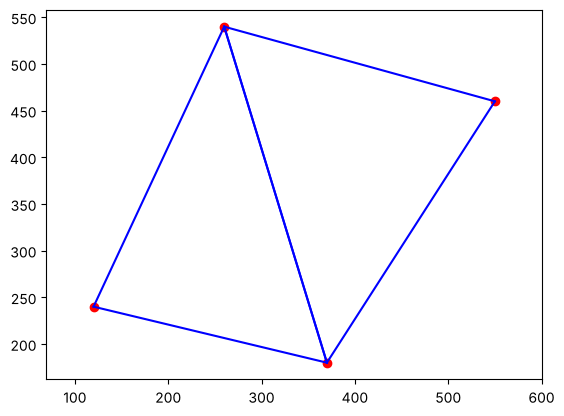

[[0, 10, 12], [0, 10, 13], [0, 12, 15], [0, 13, 15], [1, 9, 12], [1, 9, 16], [1, 12, 19], [1, 16, 18], [1, 18, 19], [2, 6, 9], [2, 6, 17], [2, 9, 15], [2, 13, 15], [2, 13, 17], [3, 5, 11], [3, 5, 18], [3, 11, 19], [3, 18, 19], [4, 7, 10], [4, 7, 11], [4, 10, 19], [4, 11, 19], [5, 8, 18], [6, 8, 9], [6, 14, 17], [8, 9, 16], [8, 16, 18], [9, 12, 15], [10, 12, 19]]


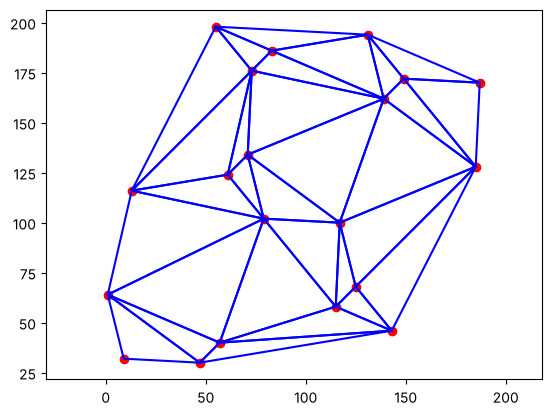

In [ ]:
class DelaunayTriangulation:
    def __init__(self, points):
        self.points = points
        self.triangles = []

    ####### TODO
    def makeDelaunay(self):
        # 분할 정복(Divide & Conquer) 들로네 삼각분할
        pts = np.asarray(self.points, dtype=float)
        n = len(pts)
        adj = {i: set() for i in range(n)}   # 간선을 인접 집합(그래프)으로 관리

        def cross(o, a, b):
            # (a - o) x (b - o) : 양수면 o->a->b 가 반시계(왼쪽 회전)
            return (pts[a][0] - pts[o][0]) * (pts[b][1] - pts[o][1]) - (pts[a][1] - pts[o][1]) * (pts[b][0] - pts[o][0])

        def in_circle(a, b, c, d):
            # d 가 삼각형 a, b, c 의 외접원 안에 있으면 True
            if cross(a, b, c) < 0:
                b, c = c, b
            m = []
            for p in (a, b, c):
                dx, dy = pts[p][0] - pts[d][0], pts[p][1] - pts[d][1]
                m.append([dx, dy, dx * dx + dy * dy])
            return np.linalg.det(np.array(m)) > 1e-9

        def add_edge(a, b):
            adj[a].add(b)
            adj[b].add(a)

        def remove_edge(a, b):
            adj[a].discard(b)
            adj[b].discard(a)

        def convex_hull(idx):
            # Monotone chain, 반시계 방향 볼록 껍질 (idx 는 x, y 순 정렬되어 있음)
            lower, upper = [], []
            for p in idx:
                while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
                    lower.pop()
                lower.append(p)
            for p in reversed(idx):
                while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
                    upper.pop()
                upper.append(p)
            return lower[:-1] + upper[:-1]

        def lower_common_tangent(L, R):
            # L 의 가장 오른쪽 점, R 의 가장 왼쪽 점에서 출발해서
            # 기준선 아래쪽(오른쪽)에 점이 있으면 그쪽으로 내려간다
            hl, hr = convex_hull(L), convex_hull(R)
            i, j = hl.index(L[-1]), hr.index(R[0])
            while True:
                moved = False
                while len(hl) > 1 and cross(hl[i], hr[j], hl[(i - 1) % len(hl)]) < 0:
                    i = (i - 1) % len(hl)      # L 은 시계 방향으로 내려감
                    moved = True
                while len(hr) > 1 and cross(hl[i], hr[j], hr[(j + 1) % len(hr)]) < 0:
                    j = (j + 1) % len(hr)      # R 은 반시계 방향으로 내려감
                    moved = True
                if not moved:
                    return hl[i], hr[j]

        def angle_from(o, ref, p, ccw=True):
            # o 에서 ref 방향을 기준으로 p 까지 회전한 각도 (0 ~ 2π)
            a1 = np.arctan2(pts[ref][1] - pts[o][1], pts[ref][0] - pts[o][0])
            a2 = np.arctan2(pts[p][1] - pts[o][1], pts[p][0] - pts[o][0])
            ang = (a2 - a1) if ccw else (a1 - a2)
            return ang % (2 * np.pi)

        def select_valid_candidate(u, v, left):
            # 기준선 (u, v) 위쪽에 있는 u 의 이웃들을 각도 순으로 정렬
            # left=True 이면 u 는 왼쪽 점(반시계로 탐색), False 이면 오른쪽 점(시계로 탐색)
            cands = [c for c in adj[u] if c != v and
                     (cross(u, v, c) > 0 if left else cross(v, u, c) > 0)]
            cands.sort(key=lambda c: angle_from(u, v, c, ccw=left))
            if not cands:
                return None
            k = 0
            # 다음 후보가 (기준선 + 현재 후보)의 외접원 안에 있으면
            # 현재 후보로 가는 간선은 들로네 조건 위반 -> 삭제
            while k + 1 < len(cands) and in_circle(u, v, cands[k], cands[k + 1]):
                remove_edge(u, cands[k])
                k += 1
            return cands[k]

        def merge(L, R):
            l, r = lower_common_tangent(L, R)   # 하단 공통 접선 = 첫 기준선
            add_edge(l, r)
            while True:                          # 지퍼 올리기
                cand_l = select_valid_candidate(l, r, left=True)
                cand_r = select_valid_candidate(r, l, left=False)
                if cand_l is None and cand_r is None:
                    break                        # 상단 공통 접선에 도달
                if cand_r is None or (cand_l is not None and not in_circle(l, r, cand_l, cand_r)):
                    add_edge(cand_l, r)          # 왼쪽 후보 승
                    l = cand_l
                else:
                    add_edge(l, cand_r)          # 오른쪽 후보 승
                    r = cand_r

        def divide_and_conquer(S):
            if len(S) == 2:                      # 기본 도형: 선분
                add_edge(S[0], S[1])
                return
            if len(S) == 3:                      # 기본 도형: 삼각형 (일직선이면 선분 2개)
                a, b, c = S
                add_edge(a, b)
                add_edge(b, c)
                if cross(a, b, c) != 0:
                    add_edge(a, c)
                return
            mid = len(S) // 2
            L, R = S[:mid], S[mid:]
            divide_and_conquer(L)
            divide_and_conquer(R)
            merge(L, R)

        # 1) x 좌표 오름차순 (같으면 y 오름차순) 정렬
        order = sorted(range(n), key=lambda i: (pts[i][0], pts[i][1]))
        if n >= 2:
            divide_and_conquer(order)

        # 2) 간선 그래프에서 삼각형 면 추출
        #    각 점의 이웃을 각도 순으로 돌며, 연속한 두 이웃이 서로 연결되어 있고
        #    반시계 방향이면 하나의 삼각형
        tri_set = set()
        for i in range(n):
            nb = sorted(adj[i], key=lambda j: np.arctan2(pts[j][1] - pts[i][1], pts[j][0] - pts[i][0]))
            for k in range(len(nb)):
                j, m = nb[k], nb[(k + 1) % len(nb)]
                if j != m and m in adj[j] and cross(i, j, m) > 0:
                    tri_set.add(tuple(sorted((i, j, m))))

        self.triangles = [
            list(t) for t in sorted(tri_set)
        ]

    ####### ~ TODO

    def plot(self):
        print(self.triangles)
        plt.figure()
        # self.triangles가 비어있으면 아무것도 연결 안 함
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[tri]
                # 삼각형의 세 변을 직접 그림
                for i in range(3):
                    x = [pts[i][0], pts[(i+1)%3][0]]
                    y = [pts[i][1], pts[(i+1)%3][1]]
                    plt.plot(x, y, 'b-')
        # 점 찍기
        plt.scatter(self.points[:, 0], self.points[:, 1], color='red')
        plt.axis('equal')
        plt.show()

for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.makeDelaunay()
    dt.plot()


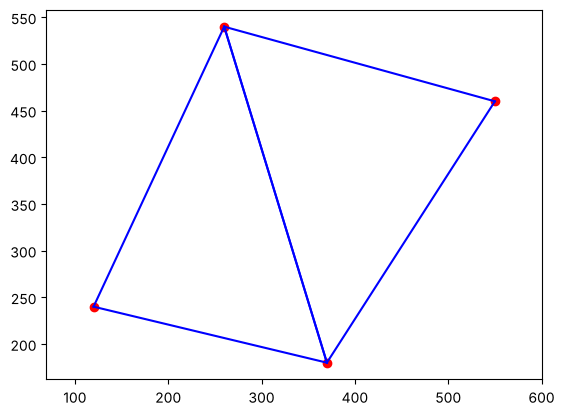

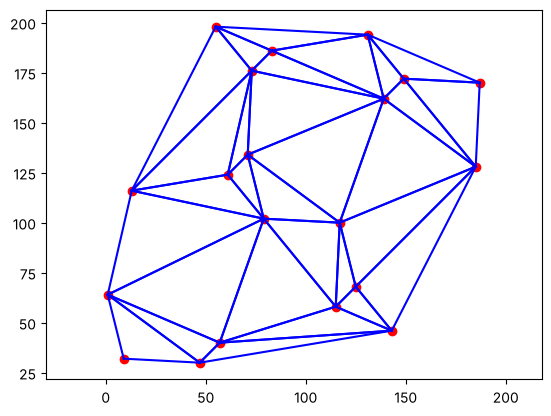

In [ ]:
from scipy.spatial import Delaunay


class DelaunayTriangulation:
    def __init__(self, points):
        self.points = points
        self.triangles = []

    def makeDelaunay(self):
        ####### TODO
        # scipy의 Delaunay가 삼각분할을 계산해 주고,
        # .simplices 에 각 삼각형의 꼭짓점 인덱스 (M, 3) 배열이 들어 있다
        tri = Delaunay(self.points)
        self.triangles = tri.simplices
        ####### ~ TODO

    def plot(self):
        plt.figure()
        self.makeDelaunay()
        # self.triangles가 비어있으면 아무것도 연결 안 함
        if len(self.triangles) > 0:
            for tri in self.triangles:
                pts = self.points[tri]
                # 삼각형의 세 변을 직접 그림
                for i in range(3):
                    x = [pts[i][0], pts[(i+1)%3][0]]
                    y = [pts[i][1], pts[(i+1)%3][1]]
                    plt.plot(x, y, 'b-')
        # 점 찍기
        plt.scatter(self.points[:, 0], self.points[:, 1], color='red')
        plt.axis('equal')
        plt.show()


for points in get_points().values():
    dt = DelaunayTriangulation(points)
    dt.plot()


100%|██████████| 9.91M/9.91M [00:01<00:00, 6.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.12MB/s]


(5000, 784)


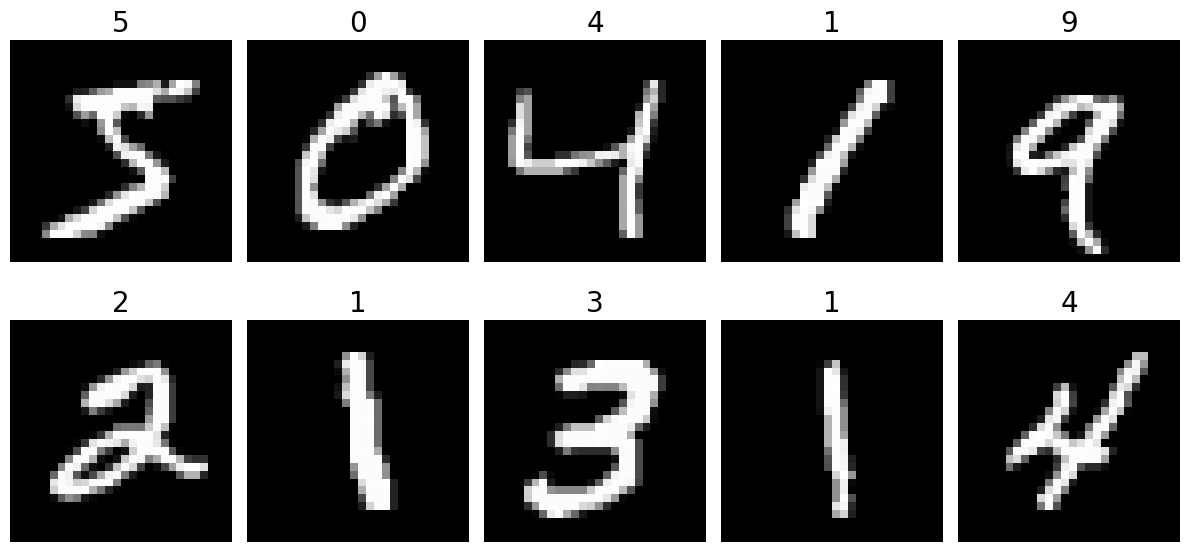

Validation accuracy: 0.938
KNN score: 0.938
k: 1, accuracy: 95.60
k: 2, accuracy: 95.00
k: 3, accuracy: 94.60
k: 4, accuracy: 93.80
k: 5, accuracy: 93.80
k: 6, accuracy: 93.40
k: 7, accuracy: 93.40
k: 8, accuracy: 93.60
k: 9, accuracy: 92.80
k: 10, accuracy: 92.80


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import torch
from torchvision import datasets, transforms

# Load MNIST dataset using torchvision
transform = transforms.Compose([transforms.ToTensor()])
mnist_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# Convert the data into numpy arrays
x_digit = mnist_data.data[:5000].numpy()
y_digit = mnist_data.targets[:5000].numpy()

# Reshape x_digit for the KNN classifier
x_digit = x_digit.reshape(-1, 28 * 28)
print(x_digit.shape)

# Visualize some samples
w, h = 2, 5
fig, axes = plt.subplots(w, h)
fig.set_size_inches(12, 6)
for i in range(w * h):
    axes[i // h, i % h].imshow(x_digit[i].reshape(28, 28), cmap='gray')
    axes[i // h, i % h].set_title(y_digit[i], fontsize=20)
    axes[i // h, i % h].axis('off')
plt.tight_layout()
plt.show()

# Split the data into train and validation sets
x_train, x_valid, y_train, y_valid = train_test_split(x_digit, y_digit, stratify=y_digit, random_state=30, test_size=0.1)

# Initialize and train the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(x_train, y_train)
prediction = knn.predict(x_valid)

# Calculate accuracy
print("Validation accuracy:", (prediction == y_valid).mean())
print("KNN score:", knn.score(x_valid, y_valid))

# Experiment with different values of k
for k in range(1, 11):
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(x_train, y_train)
    score = knn.score(x_valid, y_valid)
    print('k: %d, accuracy: %.2f' % (k, score * 100))
